<a href="https://colab.research.google.com/github/alvarogarciapiz/assets/blob/main/3_gdg_2026/03-metricas-de-rendimiento.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 3: Métricas de rendimiento

**10–15 minutos**

Ya sabemos generar texto. Ahora mediremos cuánto tarda y cómo llegan los tokens.
Usaremos **Qwen2.5-0.5B-Instruct**, más pequeño que el modelo de la primera práctica.

Abre este cuaderno en un entorno nuevo de Colab y ejecuta las celdas en orden.
GPU recomendada; también funciona en CPU, más despacio. La descarga y la carga del modelo quedan fuera de las mediciones.

## 1. Preparar y cargar
En Colab: **Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU** (Recuerda que PyTorch ya viene instalado).

In [30]:
%pip uninstall -y gradio gradio-client diffusers
%pip install -q "transformers==4.57.1" pandas matplotlib

In [31]:
%matplotlib inline

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import transformers
from IPython.display import display
from transformers import AutoModelForCausalLM, AutoTokenizer, GenerationConfig
from transformers.generation.streamers import BaseStreamer

MODEL_ID = "Qwen/Qwen2.5-0.5B-Instruct"
REVISION = "7ae557604adf67be50417f59c2c2f167def9a775"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
dtype = torch.float16 if device.type == "cuda" else torch.float32
if device.type == "cpu":
    torch.set_num_threads(min(4, os.cpu_count() or 1))

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION)
model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID, revision=REVISION, dtype=dtype, use_safetensors=True,
).to(device).eval()
# Generación greedy: misma configuración en todas las pruebas.
config = GenerationConfig.from_model_config(model.config)
config.eos_token_id = model.generation_config.eos_token_id
config.pad_token_id = tokenizer.pad_token_id
hardware = torch.cuda.get_device_name(0) if device.type == "cuda" else "CPU"

print("\n=== Modelo cargado correctamente ===\n")
print(f"Modelo:                 {MODEL_ID}")
print(f"Revisión:               {REVISION[:12]}")
print(f"Dispositivo:            {hardware}")
print(f"Precisión:              {dtype}")
print(f"Parámetros:             {sum(p.numel() for p in model.parameters()) / 1e9:.2f}B")
print(f"V. PyTorch:             {torch.__version__}")
print(f"V. Transformers:        {transformers.__version__}")


=== Modelo cargado correctamente ===

Modelo:                 Qwen/Qwen2.5-0.5B-Instruct
Revisión:               7ae557604adf
Dispositivo:            Tesla T4
Precisión:              torch.float16
Parámetros:             0.49B
V. PyTorch:             2.11.0+cu130
V. Transformers:        4.57.1


## 2. Preparar las herramientas para medir el rendimiento

Esta sección prepara el sistema para medir el rendimiento del modelo token a token. Todavía no ejecuta ninguna prueba.

En concreto se hacen dos cosas:
1. **RelojTokens** registra el instante exacto en el que el modelo entrega cada token.
2. **medir()** ejecuta una inferencia y calcula TTFT, ITL, TPOT, latencia total, tokens/s y consumo máximo de memoria GPU.


| Métrica | ¿Qué nos dice? |
|---|---|
| **TTFT** | Cuánto tarda en aparecer el primer token. |
| **ITL** | Tiempo entre tokens consecutivos (mediciones individuales). Nos permite medir p50, p90, p95... |
| **TPOT** | Tiempo medio de generación por token después del primero (media de los ITL). |
| **Latencia E2E** | Tiempo total desde que iniciamos la petición hasta obtener la respuesta. |
| **Tokens/s** | Velocidad efectiva de generación, incluyendo el tiempo inicial. |
| **Memoria GPU** | Pico de memoria utilizada durante la prueba. |

**Importante:** medimos directamente sobre el modelo, sin red ni API. Los resultados incluyen el coste de la instrumentación (medir también consume recursos) y pueden contabilizar tokens especiales como el de fin de secuencia.

In [32]:
class RelojTokens(BaseStreamer):
    def __init__(self):
        self.es_prompt = True
        self.tiempos = []

    def put(self, tokens):
        if self.es_prompt:  # generate() entrega primero el prompt completo.
            self.es_prompt = False
            return
        assert tokens.numel() == 1, "Esta práctica mide una secuencia cada vez."
        self.tiempos.append(time.perf_counter())

    def end(self):
        pass


def medir(prompt, max_new_tokens=32):
    if device.type == "cuda":
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()
    inicio = time.perf_counter()
    texto = tokenizer.apply_chat_template(
        [{"role": "user", "content": prompt}],
        tokenize=False, add_generation_prompt=True,
    )
    entradas = tokenizer(texto, return_tensors="pt", add_special_tokens=False).to(device)
    reloj = RelojTokens()
    with torch.inference_mode():
        salida = model.generate(
            **entradas, generation_config=config, do_sample=False,
            max_new_tokens=max_new_tokens, use_cache=True, streamer=reloj,
        )
    if device.type == "cuda":
        torch.cuda.synchronize()
    n_entrada = entradas["input_ids"].shape[-1]
    n_salida = salida.shape[-1] - n_entrada
    respuesta = tokenizer.decode(salida[0, n_entrada:].cpu(), skip_special_tokens=True)
    e2e = time.perf_counter() - inicio
    assert len(reloj.tiempos) == n_salida > 0
    itl = np.diff(reloj.tiempos) * 1000
    return {
        "tokens_entrada": n_entrada, "tokens_salida": n_salida,
        "prompt_KiB": len(texto.encode("utf-8")) / 1024,
        "ttft_ms": (reloj.tiempos[0] - inicio) * 1000,
        "itl_p50_ms": np.median(itl) if len(itl) else np.nan,
        "itl_p95_ms": np.percentile(itl, 95) if len(itl) else np.nan,
        "tpot_ms": np.mean(itl) if len(itl) else np.nan,
        "e2e_ms": e2e * 1000, "salida_tokens_s": n_salida / e2e,
        "gpu_pico_asignado_MiB": torch.cuda.max_memory_allocated() / 2**20 if device.type == "cuda" else np.nan,
        "gpu_pico_reservado_MiB": torch.cuda.max_memory_reserved() / 2**20 if device.type == "cuda" else np.nan,
        "llegada_ms": [(t - inicio) * 1000 for t in reloj.tiempos],
        "respuesta": respuesta,
    }

## 3. ¿Cómo afecta la longitud del prompt al rendimiento?
Solo cambia la entrada. Mantenemos modelo, precisión, generación greedy y límite de salida.
La respuesta puede terminar antes del límite: por eso contamos los tokens reales.

In [33]:
PROMPTS = {
    "Corto": "Explica en español qué es una API, en dos frases.",
    "Largo": (
        "Lee este contexto: "
        + "Una API permite que dos programas intercambien datos mediante peticiones y respuestas. " * 12
        + "Explica en español qué es una API, en dos frases."
    ),
}
REPETICIONES = 5
MAX_NUEVOS_TOKENS = 32

# Calentamiento: ejecutamos ambos prompts una vez sin registrar resultados.
for prompt in PROMPTS.values():
    medir(prompt, max_new_tokens=8)

print("Calentamiento completado. Modelo listo para medir el rendimiento.")

Calentamiento completado. Modelo listo para medir el rendimiento.


In [34]:
filas = []
inicio_lote = time.perf_counter()
for caso, prompt in PROMPTS.items():
    for repeticion in range(1, REPETICIONES + 1):
        try:
            filas.append({"caso": caso, "repeticion": repeticion, "estado": "OK", **medir(prompt, MAX_NUEVOS_TOKENS)})
        except Exception as error:
            filas.append({"caso": caso, "repeticion": repeticion, "estado": "ERROR", "error": str(error)})
segundos_lote = time.perf_counter() - inicio_lote
resultados = pd.DataFrame(filas)
correctas = resultados[resultados["estado"] == "OK"].copy()
if correctas.empty:
    display(resultados)
    raise RuntimeError("No hay generaciones correctas. Revisa los errores antes de continuar.")

columnas = ["caso", "repeticion", "tokens_entrada", "tokens_salida", "prompt_KiB",
            "ttft_ms", "itl_p50_ms", "itl_p95_ms", "tpot_ms", "e2e_ms", "salida_tokens_s"]
display(correctas[columnas].round(2))

print(f"\nPruebas completadas: {len(correctas)}/{len(resultados)}")
print(f"Tiempo total: {segundos_lote:.2f} segundos")

if (resultados["estado"] == "ERROR").any():
    display(resultados[resultados["estado"] == "ERROR"][["caso", "repeticion", "error"]])

print(f"\nEjemplo de respuesta (máximo {MAX_NUEVOS_TOKENS} tokens):")
print(correctas.iloc[0]["respuesta"])

,caso,repeticion,tokens_entrada,tokens_salida,prompt_KiB,ttft_ms,itl_p50_ms,itl_p95_ms,tpot_ms,e2e_ms,salida_tokens_s
0,Corto,1,43,32,0.19,75.55,111.77,158.86,110.70,3508.11,9.12
1,Corto,2,43,32,0.19,189.69,113.80,166.50,114.60,3743.20,8.55
2,Corto,3,43,32,0.19,102.24,61.31,124.51,78.44,2534.69,12.62
3,Corto,4,43,32,0.19,103.41,108.13,203.34,111.94,3575.84,8.95
4,Corto,5,43,32,0.19,63.19,58.88,79.47,61.52,1971.27,16.23
5,Largo,1,275,32,1.23,59.93,54.74,66.31,56.48,1811.60,17.66
6,Largo,2,275,32,1.23,64.43,54.44,68.05,56.41,1813.95,17.64
7,Largo,3,275,32,1.23,86.80,52.61,60.38,54.22,1768.50,18.09
8,Largo,4,275,32,1.23,64.48,51.51,60.08,53.04,1709.52,18.72
9,Largo,5,275,32,1.23,104.22,73.72,120.25,78.98,2553.53,12.53



Pruebas completadas: 10/10
Tiempo total: 25.02 segundos

Ejemplo de respuesta (máximo 32 tokens):
Una API (Application Programming Interface) es un conjunto de protocolos y estágios de comunicación que permiten que diferentes aplicaciones o sistemas se comunicen entre


## 4. ¿Qué nos dicen las métricas de rendimiento?

Vamos a comparar cómo afecta la longitud del prompt al rendimiento del modelo.

Nos fijaremos en cuatro aspectos:

- **TTFT:** cuánto tarda en aparecer el primer token.
- **Velocidad de generación:** cómo van llegando los tokens y cuántos genera por segundo.
- **Latencia E2E:** tiempo total hasta obtener la respuesta.
- **TPOT:** tiempo medio entre tokens generados, después del primero.

### ¿Cómo interpretamos los resultados?

- Comparamos prompts de distinta longitud, manteniendo el mismo modelo y configuración.
- Utilizamos la **mediana de cinco ejecuciones** para reducir el impacto de valores atípicos. La gráfica de llegada de tokens muestra una ejecución representativa.
- Las pruebas son **locales y secuenciales**, sin red, servidor ni peticiones simultáneas. No representan el rendimiento en producción.
- `use_cache=True` reutiliza la KV cache durante cada generación, pero no entre peticiones.
- Las mediciones de memoria GPU de PyTorch incluyen los pesos del modelo, pero no toda la VRAM utilizada por el proceso.

**¿Qué buscamos?** Comprobar si un prompt más largo aumenta el tiempo hasta el primer token, reduce la velocidad de generación o afecta a ambas métricas.

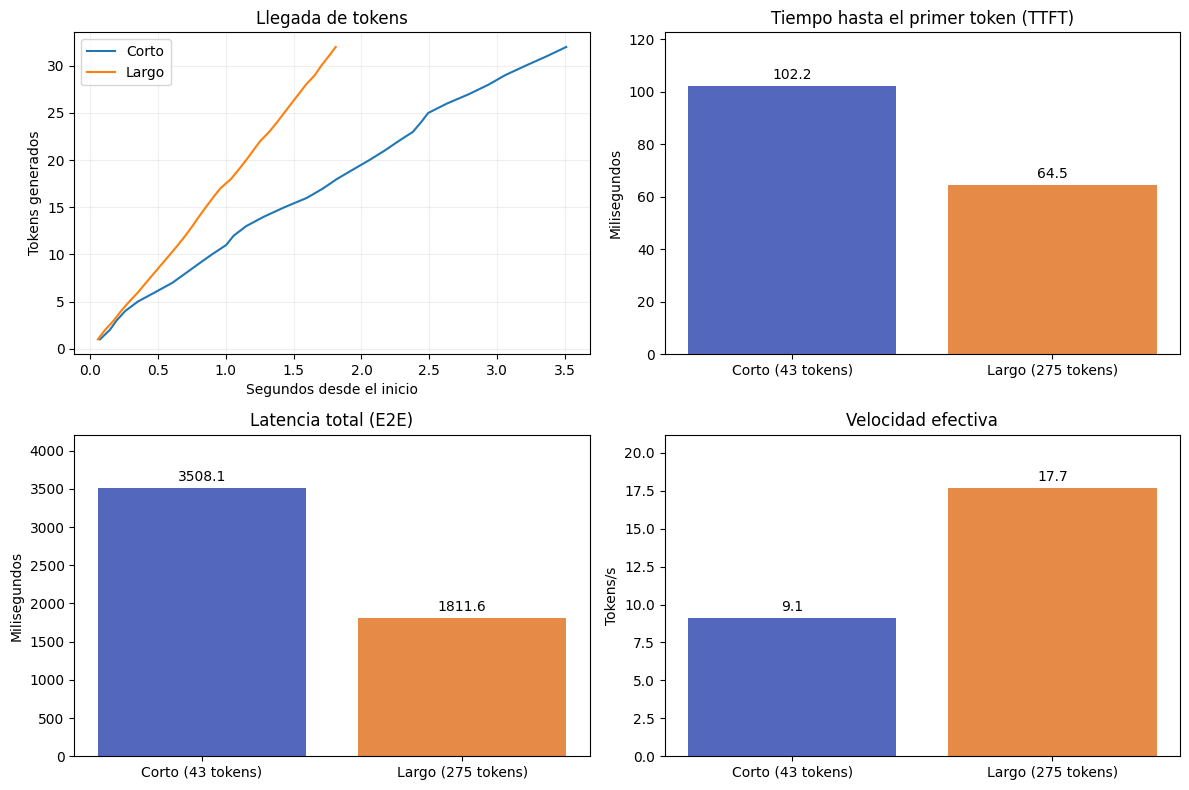

=== Resumen de rendimiento (medianas) ===


,tokens_entrada,tokens_salida,ttft_ms,tpot_ms,e2e_ms,salida_tokens_s
caso,,,,,,
Corto,43,32.0,102.24,110.70,3508.11,9.12
Largo,275,32.0,64.48,56.41,1811.60,17.66


In [35]:

# Resumir las mediciones de cada prompt.
resumen = correctas.groupby("caso", sort=False).agg(
    tokens_entrada=("tokens_entrada", "first"),
    tokens_salida=("tokens_salida", "median"),
    ttft_ms=("ttft_ms", "median"),
    tpot_ms=("tpot_ms", "median"),
    e2e_ms=("e2e_ms", "median"),
    salida_tokens_s=("salida_tokens_s", "median"),
)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
colores = ["#5368bd", "#e58b47"]
etiquetas = [
    f"{caso} ({int(fila.tokens_entrada)} tokens)"
    for caso, fila in resumen.iterrows()
]

# 1. Llegada de tokens: ejecución más cercana a la mediana.
for caso, grupo in correctas.groupby("caso", sort=False):
    indice = (grupo["e2e_ms"] - grupo["e2e_ms"].median()).abs().idxmin()
    fila = grupo.loc[indice]

    axes[0, 0].plot(
        np.array(fila["llegada_ms"]) / 1000,
        np.arange(1, len(fila["llegada_ms"]) + 1),
        label=caso,
    )

axes[0, 0].set(
    title="Llegada de tokens",
    xlabel="Segundos desde el inicio",
    ylabel="Tokens generados",
)
axes[0, 0].legend()
axes[0, 0].grid(alpha=0.2)

# 2, 3 y 4. Comparación de las medianas.
metricas = [
    ("ttft_ms", "Tiempo hasta el primer token (TTFT)", "Milisegundos"),
    ("e2e_ms", "Latencia total (E2E)", "Milisegundos"),
    ("salida_tokens_s", "Velocidad efectiva", "Tokens/s"),
]

for ax, (columna, titulo, unidad) in zip(axes.flat[1:], metricas):
    valores = resumen[columna]
    barras = ax.bar(etiquetas, valores, color=colores[:len(valores)])

    ax.set(title=titulo, ylabel=unidad)
    ax.bar_label(barras, fmt="%.1f", padding=3)
    ax.set_ylim(0, valores.max() * 1.2)

plt.tight_layout()
plt.show()

# Tabla resumen.
print("=== Resumen de rendimiento (medianas) ===")
display(resumen.round(2))


### ¿Resultados?

Al pasar de 43 a 275 tokens de entrada, el TTFT apenas cambia (46 frente a 43 ms). De hecho, el prompt largo termina antes y alcanza más tokens/s, pero estas diferencias probablemente se deban a la variabilidad de las mediciones, no a que procesar más contexto sea más rápido.

Conclusión: con prompts relativamente cortos, el impacto de la longitud puede quedar oculto por la variabilidad de ejecución.

## 5. Tu turno: ¿qué ocurre con un prompt mucho más largo?

Hasta ahora hemos comparado prompts de **43 y 275 tokens**, con diferencias de rendimiento relativamente pequeñas.

Vamos a aumentar el contexto hasta aproximadamente **2.000 tokens**, manteniendo el mismo modelo, precisión y límite de 32 tokens de salida.

**Ejecuta la siguiente celda** para repetir las mediciones y comparar automáticamente los resultados con los anteriores.

Fíjate especialmente en:

- **TTFT:** ¿tarda más en generar el primer token?
- **TPOT:** ¿cambia el tiempo medio entre tokens?
- **Latencia E2E:** ¿cuánto aumenta el tiempo total?

**¿Qué conclusiones sacas?** ¿Qué parte del rendimiento se ve más afectada por la longitud del prompt?

Fíjate en que un prompt más largo puede aumentar mucho el TTFT sin afectar apenas al TPOT. Son dos fases distintas de la inferencia.


=== Comparación de rendimiento ===


,tokens_entrada,ttft_ms,tpot_ms,e2e_ms,salida_tokens_s
Prompt original,275.0,64.48,56.41,1811.60,17.66
Prompt ampliado,1947.0,481.40,62.15,2409.06,13.28


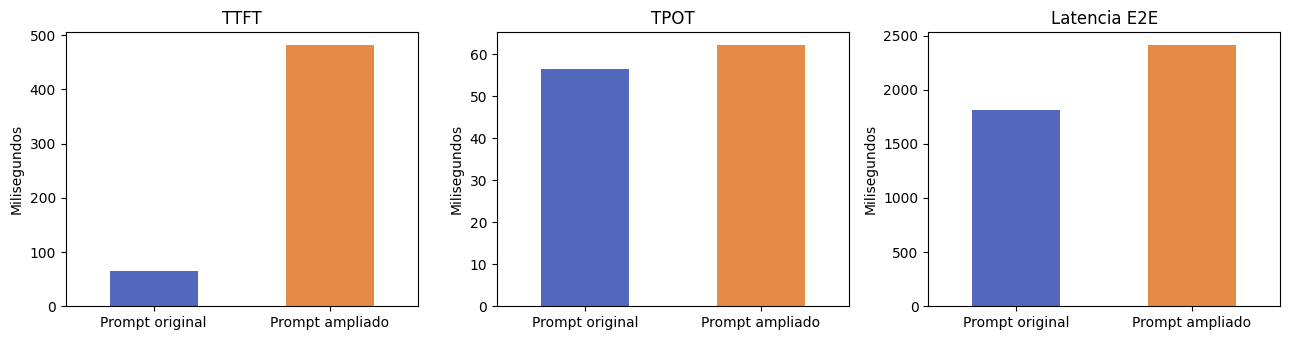

In [36]:

# Crear un prompt mucho más largo, sin modificar los originales.
prompt_extenso = (
    "Lee este contexto: "
    + "Una API permite que dos programas intercambien datos mediante peticiones y respuestas. " * 100
    + "Explica en español qué es una API, en dos frases."
)

# Calentamiento previo.
medir(prompt_extenso, max_new_tokens=8)

# Ejecutar las mismas 5 repeticiones que en la prueba original.
mediciones_extensas = pd.DataFrame([
    medir(prompt_extenso, MAX_NUEVOS_TOKENS)
    for _ in range(REPETICIONES)
])

# Comparar con los resultados anteriores.
metricas = [
    "tokens_entrada",
    "ttft_ms",
    "tpot_ms",
    "e2e_ms",
    "salida_tokens_s",
]

comparacion = pd.DataFrame({
    "Prompt original": resumen.loc["Largo", metricas],
    "Prompt ampliado": mediciones_extensas[metricas].median(),
}).T

print("\n=== Comparación de rendimiento ===")
display(comparacion.round(2))

# Visualizar las diferencias.
fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))

for ax, metrica, titulo in zip(
    axes,
    ["ttft_ms", "tpot_ms", "e2e_ms"],
    ["TTFT", "TPOT", "Latencia E2E"],
):
    comparacion[metrica].plot.bar(
        ax=ax, color=["#5368bd", "#e58b47"], rot=0
    )
    ax.set(title=titulo, ylabel="Milisegundos", xlabel="")

fig.tight_layout()
plt.show()


### Referencias
- [Modelo Qwen2.5-0.5B-Instruct](https://huggingface.co/Qwen/Qwen2.5-0.5B-Instruct)
- [Streaming de generación en Transformers](https://huggingface.co/docs/transformers/v4.57.1/en/generation_features)
- [Memoria CUDA en PyTorch](https://docs.pytorch.org/docs/stable/notes/cuda.html#cuda-memory-management)